# Гибридная система рекомендаций книг (goodbooks-10k)

Лабораторный журнал решения: вызовы функций пакета `recsys` (`src/recsys`), промежуточные таблицы и графики по этапам. Постановка, обоснования и итоговые выводы — в `README.md`. Графики, используемые в README, сохраняются в `reports/figures/`.


## Этап 0. Подготовка: загрузка данных и проверка переноса моделей


### 0.1. Загрузка и валидация данных


In [1]:
import pandas as pd

from recsys import config, data, evaluation, split
from recsys.models import ContentBased, ItemCF, Popularity, PureSVD

pd.set_option("display.float_format", "{:.4f}".format)

dataset = data.load_all()
pd.Series(data.validate(dataset), name="value").to_frame()

,value
n_ratings,5976479
n_users,53424
n_books,10000
n_tags,34252
n_book_tags,999912
book_tags_duplicate_pairs,8
book_tags_nonpositive_count,6
books_missing_original_title,585


Проверка целостности данных завершается без критических нарушений: 8 дублирующихся пар (book_id, tag_name) и 6 записей с неположительным count в book_tags, 585 книг без original_title — некритические особенности, учитываемые при очистке тегов и построении текстовых профилей. Структура датасета (5 976 479 оценок, 53 424 пользователя, 10 000 книг) совпадает с ожидаемой по домашнему заданию.


### 0.2. Split train_inner / valid


In [2]:
outer = split.temporal_split(dataset.ratings)
inner = split.temporal_split(outer.train)
train_inner, valid = inner.train, inner.test
book_tags = data.clean_book_tags(dataset)
pd.Series({"train_inner": len(train_inner), "valid": len(valid)}, name="n_ratings")

train_inner    3824978
valid           956230
Name: n_ratings, dtype: int64

Train_inner и valid получены повторным применением per-user temporal split к обучающей части outer-разбиения, без обращения к отложенной test-выборке.


### 0.3. Smoke-проверка: nDCG@10 перенесённых моделей на valid


In [3]:
eval_set = evaluation.build_eval_set(train_inner, valid)

models = {
    "Popularity (weighted)": Popularity("weighted", config.POPULARITY_WR_M),
    "Content-Based": ContentBased(dataset.books, book_tags),
    "Item-based CF": ItemCF(),
    "PureSVD": PureSVD(config.PURE_SVD_N_FACTORS),
}
for model in models.values():
    model.fit(train_inner)

smoke_table = evaluation.compare(list(models.values()), eval_set, ks=(10,)).xs(10, level="k")
smoke_table[["ndcg"]]

,ndcg
model,
"Popularity[weighted, m=100000]",0.0441
Content-Based[tags=all],0.0536
"Item-CF[adjusted_cosine, K=50, λ=50, similarity]",0.0968
PureSVD[k=200],0.0733


nDCG@10 на valid для перенесённых моделей совпадает с результатами домашнего задания с точностью до 1e-4: Popularity (weighted) 0.0441, Content-Based 0.0536, Item-based CF 0.0968, PureSVD 0.0733. Совпадение чисел подтверждает корректность переноса кода, конфигурации протокола оценки и реализации split без изменений.


## Этап 1. Расширенные признаки

Признаки пользователей, книг и пар «пользователь × книга» строятся по train_inner — выборке, на которой на этапах 2–3 подбираются веса гибрида по valid. Тематические категории определяются по тегам книг (метаданные без оценок) и не зависят от split.

### 1.1. Тематические категории книг

In [4]:
from recsys import features, plots

plots.set_style()
categories = features.book_categories(book_tags)
category_shares = pd.DataFrame(
    {
        "n_books": categories.value_counts(sort=False),
        "books": categories.value_counts(normalize=True, sort=False),
        "ratings": train_inner["book_id"].map(categories).value_counts(normalize=True, sort=False),
    }
).sort_values("books", ascending=False)
covered = (categories != config.CATEGORY_OTHER).mean()
print(f"Доля книг с категорией, отличной от other: {covered:.1%}")
category_shares

Доля книг с категорией, отличной от other: 100.0%


,n_books,books,ratings
fantasy,1751,0.1751,0.2021
mystery_thriller,1304,0.1304,0.1016
non_fiction,1026,0.1026,0.0661
romance,929,0.0929,0.0634
classics,686,0.0686,0.1596
children,678,0.0678,0.0776
science_fiction,620,0.0620,0.0793
historical_fiction,572,0.0572,0.0641
literary_fiction,552,0.0552,0.0519
young_adult,494,0.0494,0.0427


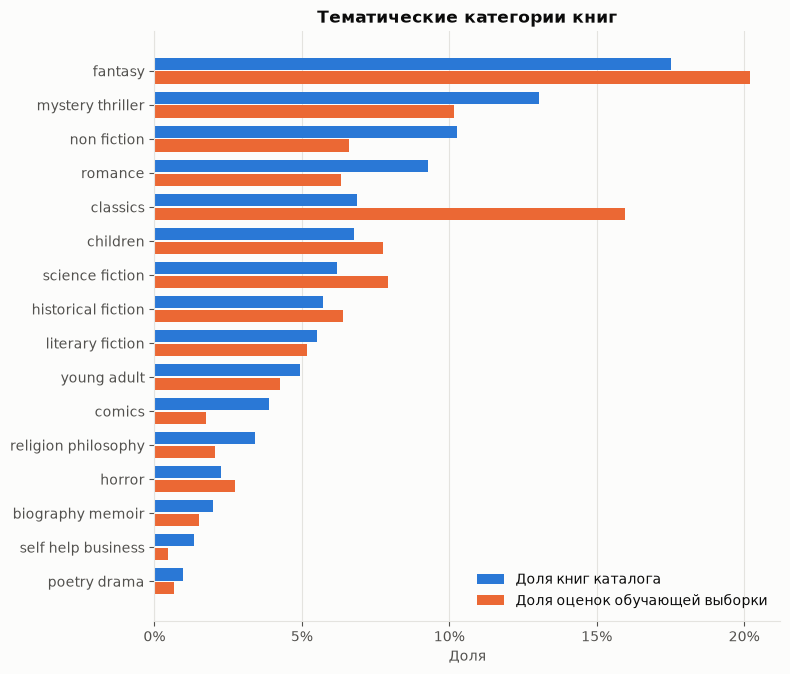

In [5]:
fig = plots.plot_category_shares(category_shares[category_shares["n_books"] > 0])
plots.save_figure(fig, "book_categories");

Категории восьми популярных книг каталога и суммы счётчиков тегов двух ведущих категорий:

In [6]:
tag_counts = features.category_tag_counts(book_tags)
example_books = [1, 2, 4, 13, 26, 35, 45, 50]
leading = tag_counts.loc[example_books].apply(
    lambda row: ", ".join(f"{c} {v:.0f}" for c, v in row.nlargest(2).items()), axis=1
)
dataset.books.set_index("book_id").loc[example_books, ["title"]].assign(
    category=categories.loc[example_books], leading_tag_counts=leading
)

,title,category,leading_tag_counts
book_id,,,
1,"The Hunger Games (The Hunger Games, #1)",science_fiction,"science_fiction 46294, young_adult 42896"
2,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy,"fantasy 68192, young_adult 22702"
4,To Kill a Mockingbird,classics,"classics 46913, historical_fiction 6097"
13,1984,science_fiction,"science_fiction 22485, classics 8853"
26,"The Da Vinci Code (Robert Langdon, #2)",mystery_thriller,"mystery_thriller 11139, literary_fiction 2259"
35,The Alchemist,religion_philosophy,"religion_philosophy 4934, classics 4096"
45,Life of Pi,literary_fiction,"literary_fiction 3843, fantasy 2548"
50,Where the Sidewalk Ends,children,"children 15001, poetry_drama 9503"


Все 10 000 книг получают одну из 16 тематических категорий: у каждой книги есть хотя бы один тег, совпадающий с шаблонами, поэтому категория other пуста и доля книг вне other составляет 100 %. Крупнейшие категории — fantasy (17.5 % книг), mystery_thriller (13.0 %) и non_fiction (10.3 %). Распределение оценок по категориям отличается от распределения книг: classics занимает 6.9 % каталога и 16.0 % оценок train_inner, fantasy — 17.5 % и 20.2 %, а у comics, religion_philosophy и self_help_business доля оценок в 1.7–2.9 раза ниже доли книг. У книг на стыке жанров категорию определяет группа тегов с наибольшей суммой счётчиков: The Hunger Games относится к science_fiction (46 294 против 42 896 у young_adult), Harry Potter and the Sorcerer's Stone — к fantasy.

### 1.2. Признаки книг

In [7]:
book_feats = features.book_features(train_inner, categories)
book_feats.describe().T

,count,mean,std,min,25%,50%,75%,max
n_ratings,10000.0000,382.4978,945.2179,1.0000,85.0000,144.0000,303.0000,18807.0000
log_n_ratings,10000.0000,5.1507,1.0980,0.6931,4.4543,4.9767,5.7170,9.8420
mean_rating,10000.0000,3.9165,0.2992,2.0421,3.7347,3.9355,4.1176,5.0000
bayes_rating,10000.0000,3.9242,0.2142,2.4013,3.7939,3.9368,4.0667,4.7258
std_rating,10000.0000,0.9274,0.1232,0.0000,0.8521,0.9233,0.9999,1.5947
low_share,10000.0000,0.0786,0.0590,0.0000,0.0389,0.0651,0.1042,0.7143


Число оценок книги в train_inner меняется от 1 до 18 807 при медиане 144, поэтому кроме числа оценок используется его логарифм. Сглаживание Bayesian average с m = 50 сжимает разброс средней оценки: стандартное отклонение уменьшается с 0.299 до 0.214, минимум поднимается с 2.04 до 2.40, максимум снижается с 5.00 до 4.73 — книги с единичными оценками больше не занимают края шкалы. Доля оценок 1–2 в среднем равна 7.9 %, у четверти книг она превышает 10.4 %.

### 1.3. Признаки пользователей

In [8]:
user_feats = features.user_features(train_inner, categories)
print(user_feats["user_type"].value_counts().to_dict())
user_feats.describe().T

{'active': 53424, 'new': 0}


,count,mean,std,min,25%,50%,75%,max
n_ratings,53424.0000,71.5966,16.6911,12.0000,62.0000,71.0000,82.0000,128.0000
mean_rating,53424.0000,3.9469,0.4679,1.0000,3.6400,3.9444,4.2614,5.0000
std_rating,53424.0000,0.8517,0.2281,0.0000,0.7186,0.8512,0.9923,1.9990
liked_share,53424.0000,0.6988,0.1863,0.0000,0.5769,0.7160,0.8429,1.0000
mainstream,53424.0000,6.9055,0.6478,4.0244,6.4783,6.9473,7.3718,8.8990
n_categories,53424.0000,9.1939,2.6893,1.0000,7.0000,10.0000,11.0000,16.0000


В train_inner у пользователей от 12 до 128 оценок (медиана 71), поэтому при пороге θ = 10 новых пользователей в реальных данных нет: тип new возникает только при симуляции cold start с усечением истории до 1, 3, 5 и 10 оценок на этапе 3. В среднем 69.9 % оценок пользователя равны 4 или 5, а профиль по категориям охватывает несколько тематик: медиана числа категорий в истории — 10 из 16. Мейнстримность (среднее log(1 + n) по прочитанным книгам) меняется от 4.02 до 8.90, то есть геометрическое среднее числа оценок прочитанных книг — от 55 до 7 300.

Пример профиля пользователя: агрегаты и пять категорий с наибольшей долей понравившихся книг; affinity — сглаженная доля.

In [9]:
profile = features.category_profile(train_inner, categories)
affinity = features.category_affinity(train_inner, categories)
example_user = int(eval_set.user_ids[0])
display(user_feats.loc[[example_user]])
pd.DataFrame(
    {"liked_share": profile.loc[example_user], "affinity": affinity[example_user - 1]}
).nlargest(5, "liked_share")

,n_ratings,mean_rating,std_rating,liked_share,mainstream,n_categories,user_type
user_id,,,,,,,
1,75,3.4933,0.9849,0.4533,7.8745,10,active


,liked_share,affinity
classics,0.3529,0.3079
literary_fiction,0.1471,0.1243
historical_fiction,0.1471,0.1288
children,0.0882,0.0870
science_fiction,0.0588,0.0637


Более трети понравившихся книг пользователя 1 (35.3 %) относится к classics. Сглаживание сдвигает эту долю к доле classics среди понравившихся оценок train_inner: affinity составляет 30.8 %.

### 1.4. Признаки взаимодействий

Признаки пар считаются по моделям, обученным на train_inner. Проверка на 2 000 пользователях выборки оценки: средние значения признаков для релевантных книг valid и для того же числа случайных книг, отсутствующих в train_inner и valid пользователя.

In [10]:
import time

import numpy as np

from recsys.models import FunkSVD

start = time.perf_counter()
funk_svd = FunkSVD().fit(train_inner)
print(f"Обучение FunkSVD на train_inner: {time.perf_counter() - start:.0f} с")

rng = np.random.default_rng(config.RANDOM_STATE)
sample = evaluation.subset(eval_set, rng.choice(eval_set.user_ids, 2_000, replace=False))
rows, cols = sample.relevant.nonzero()
pair_users = np.tile(sample.user_ids[rows], 2)
negatives = features.sample_unseen_books(
    sample.user_ids[rows], eval_set.seen + data.interaction_matrix(valid, binary=True)
)
pair_books = np.concatenate([cols + 1, negatives])

start = time.perf_counter()
pairs = features.interaction_features(
    pair_users, pair_books, models["Content-Based"], models["Item-based CF"], funk_svd,
    affinity, categories,
)  # fmt: skip
print(f"Признаки {len(pairs):,} пар: {time.perf_counter() - start:.1f} с".replace(",", " "))
pairs["pair"] = np.repeat(["релевантная (valid)", "случайная непрочитанная"], rows.size)
pairs.groupby("pair")[["content_sim", "item_cf_score", "category_affinity", "svd_rating"]].mean()

Обучение FunkSVD на train_inner: 45 с


Признаки 48 274 пар: 1.6 с


,content_sim,item_cf_score,category_affinity,svd_rating
pair,,,,
релевантная (valid),0.2392,0.1630,0.2024,4.0896
случайная непрочитанная,0.1022,0.0088,0.0916,3.9965


Все четыре признака пар в среднем выше для релевантных книг valid, чем для случайных непрочитанных: Item-CF-скор — в 18.5 раза (0.1630 против 0.0088), content_sim — в 2.3 раза (0.2392 против 0.1022), category_affinity — в 2.2 раза (0.2024 против 0.0916). Прогноз оценки FunkSVD различается меньше (4.09 против 4.00): он отражает прежде всего смещения пользователя и книги, а не вероятность того, что книга будет прочитана. Признаки 48 274 пар вычисляются примерно за 3 с, что позволяет на этапе 2 считать их на пуле кандидатов всех пользователей выборки оценки. Вклад признаков в качество рекомендаций оценивается на этапе 3 сравнением гибрида с компонентой affinity и без неё.

## Этап 2. Гибридная система: кандидаты, веса, балансировка

Гибрид собирается из моделей, обученных на train_inner (раздел 0.3 и FunkSVD из 1.4), и проверяется на valid; test на этом этапе не используется. Веса компонент — стартовые значения из `config.HYBRID_WEIGHTS`, их подбор выполняется на этапе 3.

### 2.1. Пул кандидатов

Каждый источник (Popularity, Content-Based, Item-based CF, PureSVD) даёт до 50 непрочитанных книг пользователя; списки объединяются без дубликатов с флагами источников. Recall@pool — доля релевантных книг valid, попавших в пул; `unique_share` — доля найденных релевантных книг, которые дал только этот источник.

In [11]:
from recsys import candidates, hybrid
from recsys.balancing import Quotas

component_models = {
    "popularity": models["Popularity (weighted)"],
    "content": models["Content-Based"],
    "item_cf": models["Item-based CF"],
    "pure_svd": models["PureSVD"],
    "funk_svd": funk_svd,
}
hybrid_model = hybrid.HybridRecommender(component_models, categories)
hybrid_model.fit(train_inner, fit_models=False)
scored = hybrid_model.prepare(eval_set.user_ids)
pool = scored.pool
print(f"Пул и скоры компонент для {pool.user_ids.size} пользователей: {scored.seconds:.0f} с")
display(pd.Series(pool.sizes, name="pool_size").describe().to_frame().T)
candidates.pool_metrics(pool, eval_set)

Пул и скоры компонент для 10000 пользователей: 13 с


,count,mean,std,min,25%,50%,75%,max
pool_size,10000.0000,150.5859,10.0282,96.0000,144.0000,151.0000,157.0000,188.0000


,candidates,recall,unique_share
source,,,
popularity,50.0000,0.0900,0.0958
content,49.9900,0.1248,0.1082
item_cf,49.9878,0.2110,0.1351
pure_svd,50.0000,0.1642,0.1569
pool,150.5859,0.3547,0.4961


Доли пар пула по сочетаниям источников:

In [12]:
pool.composition().head(8).to_frame()

,share
sources,
popularity,0.2322
content,0.2114
pure_svd,0.1838
item_cf,0.1033
popularity+item_cf,0.0781
item_cf+pure_svd,0.0619
content+item_cf+pure_svd,0.0408
content+pure_svd,0.0346


Пул содержит в среднем 150.6 кандидата на пользователя (от 96 до 188) при 200 возможных: 73 % пар пула предложены только одним источником. Recall@pool равен 0.355 — в 1.7 раза выше, чем у лучшего отдельного источника Item-based CF (0.211 на 50 кандидатах). Источники дополняют друг друга: 49.6 % найденных релевантных книг даёт только один источник, причём доля уникальных находок у PureSVD (15.7 %) выше, чем у Item-based CF (13.5 %), при меньшей полноте. Recall@pool ограничивает сверху полноту любой выдачи гибрида: в среднем 64.5 % релевантных книг пользователя в пул не попадают. Пул и скоры компонент для 10 000 пользователей вычисляются за 13 с.

### 2.2. Взвешенный гибрид по типам пользователей

Скор книги пула: score(u, i) = Σ_m w_m(type_u) · s̃_m(u, i), где s̃_m — скор компоненты, нормированный min-max внутри пула пользователя, type_u — new (не более 10 оценок в train) или active. Стартовые веса:

In [13]:
pd.DataFrame(config.HYBRID_WEIGHTS).rename_axis("component")

,active,new
component,,
popularity,0.0500,0.4000
content,0.1500,0.2000
item_cf,0.4000,0.1500
pure_svd,0.2000,0.0500
funk_svd,0.1000,0.0500
affinity,0.1000,0.1500


Рекомендации гибрида для всей выборки valid, проверка выдачи (K книг, без прочитанного, без повторов) и сравнение на K = 10 с отдельными моделями. Строка «Гибрид: только item_cf» — контроль нормализации и ранжирования пула: при единственной ненулевой компоненте гибрид должен воспроизводить Item-based CF.

In [14]:
start = time.perf_counter()
hybrid_recs = hybrid_model.recommend(eval_set.user_ids, 20, exclude=eval_set.seen)
hybrid_seconds = time.perf_counter() - start
print(f"Рекомендации гибрида для {eval_set.user_ids.size} пользователей: {hybrid_seconds:.0f} с")

top10 = hybrid_recs[:, :10]
seen_in_top = int(eval_set.seen[np.repeat(eval_set.user_ids, 10) - 1, top10.ravel() - 1].sum())
duplicates = sum(np.unique(row).size < row.size for row in top10)
print(f"Пустых позиций: {(top10 < 0).sum()}, прочитанных книг: {seen_in_top}")
print(f"Списков с повторами: {duplicates}")

single_models = {**models, "FunkSVD": funk_svd}
valid_recs = {
    name: model.recommend(eval_set.user_ids, 20, exclude=eval_set.seen)
    for name, model in single_models.items()
}
only_item_cf = hybrid_model.with_params(
    weights={"active": {"item_cf": 1.0}, "new": {"item_cf": 1.0}}
)
valid_recs["Гибрид: только item_cf"] = only_item_cf.rank(scored, 20)
valid_recs["Гибрид"] = hybrid_recs
columns = ["precision", "recall", "ndcg", "hit_rate", "coverage", "novelty"]
evaluation.compare_recommendations(valid_recs, eval_set).xs(10, level="k")[columns]

Рекомендации гибрида для 10000 пользователей: 13 с
Пустых позиций: 0, прочитанных книг: 0
Списков с повторами: 0


,precision,recall,ndcg,hit_rate,coverage,novelty
model,,,,,,
Popularity (weighted),0.0386,0.0323,0.0441,0.2038,0.0039,8.3973
Content-Based,0.0474,0.0411,0.0536,0.2943,0.4881,12.1374
Item-based CF,0.0842,0.0734,0.0968,0.4265,0.4086,10.8430
PureSVD,0.0646,0.0552,0.0733,0.3893,0.1963,11.1217
FunkSVD,0.0019,0.0017,0.0019,0.0151,0.0439,14.9290
Гибрид: только item_cf,0.0842,0.0734,0.0968,0.4265,0.4086,10.8429
Гибрид,0.0839,0.0725,0.0957,0.4342,0.4061,11.1059


Гибрид выдаёт по 20 книг всем 10 000 пользователям valid без пустых позиций, прочитанных книг и повторов; рекомендации формируются за 13 с. С единственной компонентой item_cf гибрид воспроизводит Item-based CF (nDCG@10 0.0968), что подтверждает корректность нормализации и ранжирования внутри пула. Со стартовыми весами nDCG@10 гибрида равен 0.0957 — на 1.1 % ниже, чем у Item-based CF. HitRate@10 при этом выше на 1.8 % (0.4342 против 0.4265), Coverage@10 близок (0.406 против 0.409), новизна больше (Novelty@10 11.11 против 10.84). Стартовые веса заданы без подбора: они подбираются по nDCG@10 на valid на этапе 3. FunkSVD как отдельная модель top-N непригоден (nDCG@10 0.0019, Novelty@10 14.93): прогноз оценки выводит в top-10 малоизвестные книги, поэтому в гибриде FunkSVD участвует только как компонента скора на пуле.

### 2.3. Балансировка разнообразия и релевантности

Жадное переранжирование пула: не более q книг одной категории в top-10 и не менее t книг вне head (1 000 самых популярных книг train_inner, 10 % каталога). Если состав пула не позволяет выполнить квоты, они ослабляются по очереди: сначала квота long tail, затем квота категорий; выбранные книги упорядочиваются по скору. Квоты действуют на весь список длины K, поэтому сбалансированные списки строятся для K = 10. `n_categories` — число различных категорий в top-10, `ild` — 1 − доля пар top-10 из одной категории, `tail_share` — доля позиций вне head.

In [15]:
balance_variants = {
    "Гибрид": hybrid_model,
    "Гибрид + квота категорий (q=3)": hybrid_model.with_params(quotas=Quotas(3, 0)),
    "Гибрид + квоты (q=3, t=3)": hybrid_model.with_params(quotas=Quotas(3, 3)),
}
balanced_recs = {name: model.rank(scored, 10) for name, model in balance_variants.items()}
balanced_recs["Item-based CF"] = valid_recs["Item-based CF"][:, :10]
category_codes = categories.cat.codes.to_numpy()
quality = evaluation.compare_recommendations(balanced_recs, eval_set, ks=(10,)).xs(10, level="k")
quality[["ndcg", "recall", "hit_rate", "coverage", "novelty"]].join(
    evaluation.diversity_metrics(balanced_recs, category_codes, hybrid_model.is_head)
)

,ndcg,recall,hit_rate,coverage,novelty,n_categories,ild,tail_share
model,,,,,,,,
Гибрид,0.0957,0.0725,0.4342,0.4061,11.1059,2.5431,0.4040,0.2739
Гибрид + квота категорий (q=3),0.0880,0.0651,0.4597,0.3904,10.7213,4.6484,0.8301,0.1951
"Гибрид + квоты (q=3, t=3)",0.0865,0.0633,0.4501,0.4477,11.1153,4.6431,0.8299,0.3156
Item-based CF,0.0968,0.0734,0.4265,0.4086,10.8430,3.3199,0.5263,0.2811


Стартовый гибрид концентрирует выдачу на любимых категориях пользователя: в top-10 в среднем 2.54 категории против 3.32 у Item-based CF, intra-list diversity — 0.404 против 0.526; компоненты content и affinity усиливают сходство с профилем. Квота q = 3 повышает число категорий до 4.65 и ILD до 0.830, а nDCG@10 снижается на 8.0 % (0.0957 → 0.0880). HitRate@10 при этом растёт на 5.9 % (0.4342 → 0.4597), а Recall@10 падает (0.0725 → 0.0651): разнообразный список чаще содержит хотя бы одну релевантную книгу, но в сумме находит меньше релевантных книг. Одна квота категорий снижает долю книг вне head с 0.274 до 0.195: место вытесненных книг любимой категории занимают популярные книги других категорий. Квота t = 3 возвращает долю long tail к 0.316 и повышает Coverage@10 на 10 % (0.406 → 0.448); nDCG@10 снижается ещё на 0.0015 (до 0.0865). Значения q и t уточняются на этапе 3.

### 2.4. Пример выдачи

Top-10 пользователя из раздела 1.3 без балансировки (источники кандидата, категория, нормированные скоры компонент) и с квотами q = 3, t = 3:

In [16]:
display(hybrid_model.explain(example_user, dataset.books).round(3))
balance_variants["Гибрид + квоты (q=3, t=3)"].explain(example_user, dataset.books)[
    ["book_id", "title", "category", "head", "sources", "score"]
].round(3)

,book_id,title,category,head,sources,popularity,content,item_cf,pure_svd,funk_svd,affinity,score
position,,,,,,,,,,,,
1,76,Sense and Sensibility,classics,True,content+item_cf+pure_svd,0.3300,0.7660,0.9420,0.4600,0.5180,1.0000,0.7520
2,14,Animal Farm,classics,True,content+item_cf,0.1690,0.7850,0.8360,0.2780,0.5980,1.0000,0.6760
3,225,East of Eden,classics,True,popularity+content+item_cf,0.4110,0.7130,0.8310,0.1700,0.7650,1.0000,0.6700
4,172,Anna Karenina,classics,True,content+item_cf+pure_svd,0.2990,0.8980,0.3910,1.0000,0.6050,1.0000,0.6660
5,485,The Brothers Karamazov,classics,True,content+item_cf+pure_svd,0.3340,0.8350,0.4900,0.5940,0.7110,1.0000,0.6280
6,265,A Tree Grows in Brooklyn,classics,True,popularity+item_cf,0.3820,0.6490,0.6610,0.3680,0.7200,1.0000,0.6260
7,28,Lord of the Flies,classics,True,content+item_cf,0.0290,0.9490,0.6880,0.2470,0.4170,1.0000,0.6100
8,1,"The Hunger Games (The Hunger Games, #1)",science_fiction,True,popularity+item_cf,0.8860,0.1010,1.0000,0.3290,0.5340,0.1950,0.5980
9,195,The Guernsey Literary and Potato Peel Pie Society,historical_fiction,True,item_cf+pure_svd,0.3460,0.2990,0.6200,0.8630,0.6360,0.4100,0.5870


,book_id,title,category,head,sources,score
position,,,,,,
1,76,Sense and Sensibility,classics,True,content+item_cf+pure_svd,0.7520
2,14,Animal Farm,classics,True,content+item_cf,0.6760
3,225,East of Eden,classics,True,popularity+content+item_cf,0.6700
4,1,"The Hunger Games (The Hunger Games, #1)",science_fiction,True,popularity+item_cf,0.5980
5,195,The Guernsey Literary and Potato Peel Pie Society,historical_fiction,True,item_cf+pure_svd,0.5870
6,25,Harry Potter and the Deathly Hallows (Harry Po...,fantasy,True,popularity+item_cf,0.5810
7,291,Cutting for Stone,historical_fiction,True,popularity+item_cf+pure_svd,0.5800
8,2,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy,True,popularity+item_cf,0.5770
9,15,The Diary of a Young Girl,non_fiction,True,popularity+item_cf,0.5420


У пользователя 1 (classics — 35.3 % понравившихся книг) семь из десяти книг выдачи без балансировки относятся к classics: нормированная affinity к этой категории равна 1.0 и вместе с content поднимает книги одного жанра. Квота q = 3 заменяет четыре книги classics книгами historical_fiction, fantasy, non_fiction и biography_memoir — в выдаче шесть категорий вместо четырёх. Книг вне head в выдаче нет: квота t для этого пользователя невыполнима и снимается при ослаблении квот. Каждая книга обеих выдач предложена как минимум двумя источниками, и среди них всегда есть Item-based CF.